Clearning Data load

In [151]:
import pandas as pd
import numpy as np
from pathlib import Path
try:

    path = Path("student_learning.csv")  # Assign the resulting value to this variable for later use.
    df1 = pd.read_csv(path)  # Read the CSV file into a Pandas DataFrame.
    print("Dataset shape:", df1.shape)  # Display the computed value or model result.
    print(df1.head(3))  # Display the computed value or model result.
except FileNotFoundError:
    print("Student_learning file not found . please upload and try again")

Dataset shape: (280, 7)
   hours_studied  attendance  practice_tests  sleep_hours study_method  \
0            7.5          54               0          5.6        video   
1            4.4          61               0          6.0        video   
2            8.2          63               1          5.2        group   

   final_score  passed  
0           48       0  
1           50       0  
2           73       1  


Messy data load

In [152]:
import pandas as pd
import numpy as np
from pathlib import Path
try:

    path = Path("student_learning_messy.csv")  # Assign the resulting value to this variable for later use.
    df2 = pd.read_csv(path)  # Read the CSV file into a Pandas DataFrame.
    print("Dataset shape:", df2.shape)  # Display the computed value or model result.
    print(df2.head(3))  # Display the computed value or model result.
except FileNotFoundError:
    print("Student_learning file not found . please upload and try again")

Dataset shape: (280, 7)
   hours_studied  attendance  practice_tests  sleep_hours study_method  \
0            NaN        54.0               0          5.6        video   
1            4.4        61.0               0          NaN        video   
2            8.2        63.0               1          5.2          NaN   

   final_score  passed  
0          NaN     0.0  
1         50.0     0.0  
2          NaN     1.0  


In [153]:
from sklearn.model_selection import train_test_split
# num = ["hours_studied", "attendance", "practice_tests", "sleep_hours"]
X = df2.drop(columns=["passed"])
y = df2["passed"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Training:", X_train.shape, "Testing:", X_test.shape)

ValueError: Input y contains NaN.

In [ ]:
# for an introductory example
from sklearn.model_selection import train_test_split

# except passed column, all other columns are features
Xn = df2.drop(columns=["passed"])
target = df2["passed"]

Xt, xv, yt, yv = train_test_split(
    Xn, y, test_size=.20, random_state=42, stratify=y
)

features = ["hours_studied","attendance"]
print("Ready for numberical demonstrations.")

Ready for numberical demonstrations.


Checking missing values
- isnull()
- isna()

In [ ]:
# Missing values in the dataset 2
df2.isnull().sum()

hours_studied     1
attendance        1
practice_tests    0
sleep_hours       2
study_method      2
final_score       6
passed            1
dtype: int64

In [ ]:
# check the datatype of dataframe 2
df2.dtypes

hours_studied     float64
attendance        float64
practice_tests      int64
sleep_hours       float64
study_method          str
final_score       float64
passed            float64
dtype: object

In [ ]:
# missing values in dataframe 1
df1.isna().sum()

hours_studied     0
attendance        0
practice_tests    0
sleep_hours       0
study_method      0
final_score       0
passed            0
dtype: int64

Pre-Processing
- handling missing values using statistics methods: mean, median, mode

SimpleImputer: Stragtegy have four values these like
`median, mean, most_frequent, constant`

In [ ]:
# example for missing values imputation using sklearn on sample/dummy data
import numpy as np
from sklearn.impute import SimpleImputer

a = np.array([[2, 3], [np.nan, 5], [8, 3], [np.nan, 2], [6, 1], [np.nan, 4]])

print(f"Before imputation:\n{a}")

imputer = SimpleImputer(strategy='median')
imputer_m = SimpleImputer(strategy='mean')

a_median = imputer.fit_transform(a)
a_mean = imputer_m.fit_transform(a)

print(f"\nAfter median imputation:\n{a_median}")
print(f"\nAfter mean imputation:\n{a_mean}")

Before imputation:
[[ 2.  3.]
 [nan  5.]
 [ 8.  3.]
 [nan  2.]
 [ 6.  1.]
 [nan  4.]]

After median imputation:
[[2. 3.]
 [6. 5.]
 [8. 3.]
 [6. 2.]
 [6. 1.]
 [6. 4.]]

After mean imputation:
[[2.         3.        ]
 [5.33333333 5.        ]
 [8.         3.        ]
 [5.33333333 2.        ]
 [6.         1.        ]
 [5.33333333 4.        ]]


In [ ]:
# I need columns names so we already knew that
df2.columns

Index(['hours_studied', 'attendance', 'practice_tests', 'sleep_hours',
       'study_method', 'final_score', 'passed'],
      dtype='str')

In [ ]:
# perfroming missing values imputation on the dataframe 2 using median strategy

# use only numerical features for imputation: string features per imputation nahi hoti
df2_a = df2[['hours_studied', 'attendance', 'practice_tests', 'sleep_hours',
       'final_score', 'passed']].values

# to handle string missing values
df2_b = df2[["study_method"]].values

# use median strategy
imputer = SimpleImputer(strategy='median')
# fit transform on imputer
df2_a_median = imputer.fit_transform(df2_a)

# imputation on string column
imputer_b = SimpleImputer(strategy='most_frequent')
df2_b_ = imputer_b.fit_transform(df2_b)

print(f"After median imputation on numerical features:\n{df2_a_median}")
print(f"After most frequent imputation on string features:\n{df2_b_}")


After median imputation on numerical features:
[[ 4.8 54.   0.   5.6 59.5  0. ]
 [ 4.4 61.   0.   6.6 50.   0. ]
 [ 8.2 63.   1.   5.2 59.5  1. ]
 ...
 [ 5.  76.   4.   6.3 54.   0. ]
 [ 8.4 80.   0.   6.9 82.   1. ]
 [ 8.2 76.   2.   5.3 72.   1. ]]
After most frequent imputation on string features:
[['video']
 ['video']
 ['self']
 ['self']
 ['self']
 ['video']
 ['self']
 ['self']
 ['self']
 ['group']
 ['group']
 ['group']
 ['group']
 ['self']
 ['video']
 ['self']
 ['group']
 ['self']
 ['video']
 ['self']
 ['self']
 ['self']
 ['self']
 ['self']
 ['group']
 ['self']
 ['video']
 ['self']
 ['group']
 ['self']
 ['group']
 ['group']
 ['self']
 ['video']
 ['self']
 ['self']
 ['group']
 ['video']
 ['self']
 ['self']
 ['video']
 ['group']
 ['video']
 ['group']
 ['group']
 ['self']
 ['video']
 ['self']
 ['group']
 ['self']
 ['group']
 ['group']
 ['group']
 ['video']
 ['self']
 ['group']
 ['self']
 ['self']
 ['self']
 ['self']
 ['self']
 ['group']
 ['group']
 ['group']
 ['self']
 ['self']
 ['se

Categorical: useing the Coding techniques like; onehot, etc...

In [ ]:
# example of onehot encoding on the sample/dummy dataframe

import numpy as np
from sklearn.preprocessing import OneHotEncoder

# Sample data: 2 features (e.g., Color and Size)
X = np.array([
    ['red', 'small'],
    ['green', 'medium'],
    ['blue', 'large']

])

# Manually define the allowed categories for each column:
# Column 0 ('red', 'blue', 'green', 'yellow')
# Column 1 ('small', 'medium', 'large')
custom_categories = [
    ['red', 'blue', 'green', 'yellow'],  # 'yellow' isn't in X, but will get a column
    ['small', 'medium', 'large']
]

encoder = OneHotEncoder(categories=custom_categories, sparse_output=False)

# Fit and transform
encoded_data = encoder.fit_transform(X)

print(encoded_data)


[[1. 0. 0. 0. 1. 0. 0.]
 [0. 0. 1. 0. 0. 1. 0.]
 [0. 1. 0. 0. 0. 0. 1.]]


In [ ]:
# using onehot encoding on datafeame 2

from sklearn.preprocessing import OneHotEncoder

d = df2[["study_method"]]

print(f"Before OneHotEncoder:\n{d[:5]}")

enc = OneHotEncoder(sparse_output=False,
                    handle_unknown="ignore")

result = enc.fit_transform(d)

print(f"\nAfter OneHotEncoder:\n{result[:5]}")

Before OneHotEncoder:
  study_method
0        video
1        video
2          NaN
3         self
4         self

After OneHotEncoder:
[[0. 0. 1. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]
 [0. 1. 0. 0.]
 [0. 1. 0. 0.]]


Feature Scaling

Large megniture feature scale in standard values
Feature Scaling: Mean, std, transform

In [ ]:
from sklearn.preprocessing import StandardScaler

a = [[1.], [2.], [3.], [4.], [5.]]
print(f"Before StandardScaler:\n{a}")

# using the scaler instance and make it fit  
scaler = StandardScaler()
result = scaler.fit_transform(a).round(2)

print(f"\nAfter StandardScaler:\n{result}")

Before StandardScaler:
[[1.0], [2.0], [3.0], [4.0], [5.0]]

After StandardScaler:
[[-1.41]
 [-0.71]
 [ 0.  ]
 [ 0.71]
 [ 1.41]]


Column Transformer

In [ ]:
# Using the columntransformer practice on the dummy/dataframe sample records.
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
dff = pd.DataFrame({
    'hours_studied': [1, 2, 3, 4,5],
    'study_method': ["Book", "Video","Book", "Online", "Video"]
})
print(f"Before ColumnTransformer:\n{dff}")

prep = ColumnTransformer(
    transformers=[
        ('scaler', StandardScaler(), ['hours_studied']),
        ('encoder', OneHotEncoder(sparse_output=False, handle_unknown="ignore"), ['study_method'])
    ]
)

# fit the dataframe in columntransformer instance
dff_transformed = prep.fit_transform(dff)
print(f"\nAfter ColumnTransformer:\n{dff_transformed}")

# retrieve readable headers
columns = prep.get_feature_names_out()
transformed_dff = pd.DataFrame(dff_transformed, columns=columns)

Before ColumnTransformer:
   hours_studied study_method
0              1         Book
1              2        Video
2              3         Book
3              4       Online
4              5        Video

After ColumnTransformer:
[[-1.41421356  1.          0.          0.        ]
 [-0.70710678  0.          0.          1.        ]
 [ 0.          1.          0.          0.        ]
 [ 0.70710678  0.          1.          0.        ]
 [ 1.41421356  0.          0.          1.        ]]


In [ ]:
print("After ColumnTransformer with readable headers:")
transformed_dff

After ColumnTransformer with readable headers:


,scaler__hours_studied,encoder__study_method_Book,encoder__study_method_Online,encoder__study_method_Video
0,-1.414214,1.0,0.0,0.0
1,-0.707107,0.0,0.0,1.0
2,0.000000,1.0,0.0,0.0
3,0.707107,0.0,1.0,0.0
4,1.414214,0.0,0.0,1.0


In [ ]:
# testing on the dataframe 2
from sklearn.compose import ColumnTransformer

df = df2.copy()
prep = ColumnTransformer(
    transformers=[
        ('scaler', StandardScaler(), ['hours_studied', 'attendance', 'practice_tests', 'sleep_hours',
'final_score', 'passed']),
        ('encoder', OneHotEncoder(sparse_output=False, handle_unknown="ignore"), ['study_method'])
    ]
)

df_transformed = prep.fit_transform(df)
print(f"\nAfter ColumnTransformer:\n{df_transformed}")

# retrieve readable headers
columns = prep.get_feature_names_out()
transformed_df = pd.DataFrame(df_transformed, columns=columns)



After ColumnTransformer:
[[        nan -1.59447985 -1.60182693 ...  0.          1.
   0.        ]
 [-0.18384765 -1.08961293 -1.60182693 ...  0.          1.
   0.        ]
 [ 1.29166543 -0.94536524 -1.09617694 ...  0.          0.
   1.        ]
 ...
 [ 0.0491281  -0.00775525  0.42077303 ...  0.          1.
   0.        ]
 [ 1.36932401  0.28074013 -1.60182693 ...  0.          0.
   0.        ]
 [ 1.29166543 -0.00775525 -0.59052695 ...  0.          1.
   0.        ]]


In [ ]:
print("After ColumnTransformer with readable headers:")
transformed_df[:5]

After ColumnTransformer with readable headers:


,scaler__hours_studied,scaler__attendance,scaler__practice_tests,scaler__sleep_hours,scaler__final_score,scaler__passed,encoder__study_method_group,encoder__study_method_self,encoder__study_method_video,encoder__study_method_nan
0,NaN,-1.594480,-1.601827,-0.785079,NaN,-0.887954,0.0,0.0,1.0,0.0
1,-0.183848,-1.089613,-1.601827,NaN,-0.531720,-0.887954,0.0,0.0,1.0,0.0
2,1.291665,-0.945365,-1.096177,-1.084875,NaN,1.126185,0.0,0.0,0.0,1.0
3,0.748055,-0.873241,-1.096177,NaN,-0.339853,-0.887954,0.0,1.0,0.0,0.0
4,-1.387556,0.208616,0.926423,-0.635180,NaN,NaN,0.0,1.0,0.0,0.0


__PipeLine__

Raw data -> Preprocessor -> Cassifier

In [154]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

prep = ColumnTransformer([
    ("num", StandardScaler(), ['hours_studied', 'attendance', 'practice_tests', 'sleep_hours',
       'final_score']),
    ("cat", OneHotEncoder(sparse_output=False, handle_unknown="ignore"), ["study_method"])
])

dff2 = prep.fit_transform(df)

# make our pipeline for model
pipe = Pipeline([
    ("preprocess", prep),
    ("model", LogisticRegression(max_iter=1000))
])

pipe.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['hours_studied','attendance','practice_tests','sleep_hours', 'study_method','final_score']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='pass

**Feature Engineering**

In [121]:
# making new features by taking existing feature; this is called feature engineering
df1["study_mintues"] = df1["hours_studied"] * 60
df1["study_seconds"] = df1["hours_studied"] * 3600

df1.head(3)

,hours_studied,attendance,practice_tests,sleep_hours,study_method,final_score,passed,study_mintues,study_seconds
0,7.5,54,0,5.6,video,48,0,450.0,27000.0
1,4.4,61,0,6.0,video,50,0,264.0,15840.0
2,8.2,63,1,5.2,group,73,1,492.0,29520.0


---

## Unsupervised Learning

K-means clustering: Find groups without knowing a target.

In [159]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

ai = df1[["hours_studied", "attendance"]]

z = StandardScaler().fit_transform(ai)

km = KMeans(n_clusters=10, random_state=42, n_init=10)

df1["Cluster"] = km.fit_predict(z)
df1.sample(5)

,hours_studied,attendance,practice_tests,sleep_hours,study_method,final_score,passed,Cluster
17,1.1,90,2,5.0,self,32,0,8
114,2.1,53,4,5.1,group,69,1,5
37,4.8,85,5,5.9,video,64,1,3
40,4.4,96,4,4.5,video,61,0,7
69,4.4,57,0,7.3,self,25,0,2


In [161]:
df1.groupby("Cluster")[["hours_studied", "attendance"]].mean()

,hours_studied,attendance
Cluster,,
0,8.276471,76.000000
1,2.054545,73.393939
2,4.066667,62.629630
3,5.200000,80.541667
4,8.412500,57.687500
5,1.653571,58.000000
6,6.509091,61.090909
7,5.289189,94.756757
8,1.975758,89.757576


In [160]:
# check the cluster size
df1.groupby("Cluster").size()

Cluster
0    34
1    33
2    27
3    24
4    16
5    28
6    22
7    37
8    33
9    26
dtype: int64

In [ ]:
# testing more columns on cluster part
ai_m = df1[['hours_studied', 'attendance', 'practice_tests', 'sleep_hours',
       'final_score', 'passed']]

zm = StandardScaler().fit_transform(ai_m)

km_m = KMeans(n_clusters=10, random_state=42, n_init=10)

df1["Cluster_m"] = km.fit_predict(zm)
df1.sample(5)

,hours_studied,attendance,practice_tests,sleep_hours,study_method,final_score,passed,Cluster,Cluster_m
161,8.7,59,5,7.8,group,78,1,4,2
10,3.8,92,2,9.0,group,62,1,7,7
183,3.3,66,6,6.6,self,59,0,2,1
12,6.3,96,5,8.2,group,76,1,7,3
79,7.6,81,4,8.3,group,83,1,0,3


In [166]:
print(df1.groupby("Cluster_m").size(),"\n")
print(df1.groupby("Cluster")[["hours_studied", "attendance"]].mean())

Cluster_m
0    26
1    33
2    27
3    23
4    33
5    24
6    42
7    23
8    26
9    23
dtype: int64 

         hours_studied  attendance
Cluster                           
0             8.276471   76.000000
1             2.054545   73.393939
2             4.066667   62.629630
3             5.200000   80.541667
4             8.412500   57.687500
5             1.653571   58.000000
6             6.509091   61.090909
7             5.289189   94.756757
8             1.975758   89.757576
9             7.630769   89.038462


In [169]:
# check the aggregate (min, max)
print("Mean",df1.groupby("Cluster")[["hours_studied", "attendance"]].mean()[:5],"\n")
print("Minimum",df1.groupby("Cluster")[["hours_studied", "attendance"]].min()[:5],"\n")
print("Maximum",df1.groupby("Cluster")[["hours_studied", "attendance"]].max()[:5])

Mean          hours_studied  attendance
Cluster                           
0             8.276471   76.000000
1             2.054545   73.393939
2             4.066667   62.629630
3             5.200000   80.541667
4             8.412500   57.687500 

Minimum          hours_studied  attendance
Cluster                           
0                  7.2          68
1                  0.7          66
2                  3.2          54
3                  3.8          73
4                  7.4          52 

Maximum          hours_studied  attendance
Cluster                           
0                  9.4          83
1                  3.3          80
2                  4.9          71
3                  6.6          87
4                  9.2          63


In [171]:
# Describing each cluster of selected features
df1.groupby("Cluster")[["hours_studied", "attendance"]].describe()

hours_studied                                                    \
                count      mean       std  min    25%   50%    75%  max   
Cluster                                                                   
0                34.0  8.276471  0.684486  7.2  7.625  8.25  8.875  9.4   
1                33.0  2.054545  0.811284  0.7  1.600  2.00  2.700  3.3   
2                27.0  4.066667  0.546316  3.2  3.500  4.20  4.550  4.9   
3                24.0  5.200000  0.795640  3.8  4.675  5.05  5.750  6.6   
4                16.0  8.412500  0.621691  7.4  7.875  8.60  8.900  9.2   
5                28.0  1.653571  0.701576  0.6  1.075  1.70  2.025  3.1   
6                22.0  6.509091  0.624812  5.5  5.925  6.60  6.800  7.7   
7                37.0  5.289189  0.938315  3.6  4.500  5.50  5.900  7.0   
8                33.0  1.975758  0.761179  0.7  1.500  1.80  2.600  3.3   
9                26.0  7.630769  0.754066  6.4  7.050  7.60  8.000  9.2   

        attendance                                                        
             count       mean       std   min    25%   50%    75%    max  
Cluster                                                                   
0             34.0  76.000000  4.334499  68.0  72.00  76.5  79.75   83.0  
1             33.0  73.393939  4.344101  66.0  70.00  74.0  77.00   80.0  
2             27.0  62.629630  5.350400  54.0  57.50  63.0  67.00   71.0  
3             24.0  80.541667  4.403350  73.0  76.00  81.5  84.00   87.0  
4             16.0  57.687500  3.113813  52.0  54.75  58.5  59.25   63.0  
5             28.0  58.000000  3.527668  53.0  55.75  58.0  60.25   65.0  
6             22.0  61.090909  4.471168  53.0  58.25  62.0  65.00   68.0  
7             37.0  94.756757  3.226672  89.0  92.00  95.0  97.00  100.0  
8             33.0  89.757576  5.590339  82.0  86.00  89.0  93.00  100.0  
9             26.0  89.038462  4.132610  82.0  86.00  89.0  91.50   99.0

In [172]:
df1.groupby("Cluster_m")[["hours_studied", "attendance"]].describe()

hours_studied                                                    \
                  count      mean       std  min    25%   50%    75%  max   
Cluster_m                                                                   
0                  26.0  6.296154  2.172092  1.4  4.725  7.45  7.975  9.2   
1                  33.0  2.318182  1.346165  0.6  1.500  1.90  3.400  5.8   
2                  27.0  7.774074  1.418448  4.5  6.700  8.00  8.850  9.4   
3                  23.0  5.300000  1.631508  1.8  4.350  5.50  6.250  8.0   
4                  33.0  3.990909  2.261134  0.7  2.600  3.10  6.200  8.5   
5                  24.0  2.200000  1.091469  0.7  1.400  1.95  3.125  4.4   
6                  42.0  2.900000  1.547618  0.8  1.600  2.60  3.875  6.5   
7                  23.0  6.882609  1.643071  3.8  5.850  6.70  8.300  9.2   
8                  26.0  6.807692  1.369065  4.2  5.850  6.90  7.575  9.2   
9                  23.0  6.678261  1.504828  4.6  5.300  6.50  7.650  9.2   

          attendance                                                         
               count       mean        std   min    25%   50%    75%    max  
Cluster_m                                                                    
0               26.0  77.615385  12.364714  53.0  70.00  78.0  88.25   97.0  
1               33.0  63.606061   7.487237  53.0  58.00  65.0  67.00   88.0  
2               27.0  62.333333   7.625867  54.0  57.50  59.0  67.00   79.0  
3               23.0  87.782609   8.339155  76.0  80.50  89.0  95.50  100.0  
4               33.0  81.575758   9.127672  67.0  74.00  84.0  89.00  100.0  
5               24.0  61.375000   6.882950  53.0  56.75  59.0  64.50   77.0  
6               42.0  84.166667   9.537900  63.0  78.00  83.0  92.00  100.0  
7               23.0  87.434783   8.983956  68.0  82.00  90.0  93.00   99.0  
8               26.0  66.423077  10.856051  52.0  58.25  62.5  74.50   88.0  
9               23.0  89.000000   7.373170  78.0  82.50  89.0  96.50  100.0

In [176]:
# inspecting the specific group
check = int(input("Only number from 0 to 9.\nInspect specific cluster:"))
df1[df1["Cluster_m"] == check]

,hours_studied,attendance,practice_tests,sleep_hours,study_method,final_score,passed,Cluster,Cluster_m
5,9.3,72,5,7.0,video,84,1,0,2
6,7.4,54,5,8.1,self,62,1,4,2
11,8.8,54,4,7.5,group,67,1,4,2
13,7.9,57,5,8.6,self,75,1,4,2
29,6.6,59,5,6.8,self,66,1,6,2
60,6.5,59,4,7.7,self,62,1,6,2
82,7.8,58,6,6.5,self,62,1,4,2
91,6.8,65,5,6.4,group,86,1,6,2
100,8.7,79,4,7.8,self,78,1,0,2
103,9.2,75,4,7.2,video,63,1,0,2


C:\Users\786\AppData\Local\Temp\ipykernel_21124\760395871.py:11: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


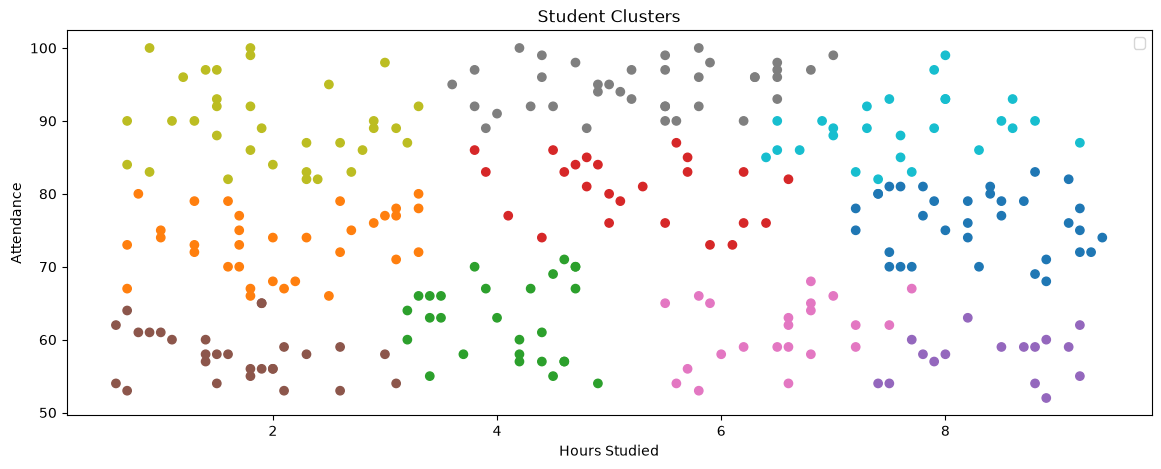

In [191]:
# scatter chart to display the clusters
import matplotlib.pyplot as plt
plt.figure(figsize=(14, 5))
x = df1["hours_studied"]
y = df1["attendance"]
plt.scatter(x, y, c=df1["Cluster"], cmap="tab10")

plt.xlabel("Hours Studied")
plt.ylabel("Attendance")
plt.title("Student Clusters")
plt.legend()
plt.show()

Choosing k and understanding : a pattern, not a diagonsis

low inertia is good.
elbow: tell us number of cluster


In [204]:
# check the inertia
for k in range(1, 21):
    m_inertia = KMeans(n_clusters=k, random_state=42, n_init=10)
    a_inertia = df1[["hours_studied", "attendance"]]
    f_in = StandardScaler().fit_transform(a_inertia)
    m_inertia.fit(f_in)
    print(k, round(m_inertia.inertia_, 1))

1 560.0
2 338.2
3 197.3
4 133.8
5 105.8
6 88.1
7 74.8
8 63.2
9 54.3
10 49.4
11 44.6
12 41.1
13 37.1
14 33.6
15 31.7
16 30.0
17 28.1
18 26.6
19 24.8
20 23.3


__HyperParameter Tunning__

Depth, number of clusters, iterations

In [205]:
from sklearn.model_selection import GridSearchCV

from sklearn.tree import DecisionTreeClassifier

search = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    {"max_depth": [2, 3, 6]}, cv=5
)
search.fit(X_train[num], y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [2, 3, ...]}"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with hig

In [208]:
# checking the best parameter
print(search.best_params_)
print(search.best_score_)

{'max_depth': 2}
0.816969696969697


__Save, load and Run__: now we have to save the model for check the new Prediction.

artifact: initial pipeline(we already work), `joblib.dump()`, `joblib.load()`

for doing this we'll use `joblib` library.

In [209]:
import joblib
# save model
joblib.dump(pipe, "Student_model.joblib")

['Student_model.joblib']

In [220]:
# load our model
loaded = joblib.load("Student_model.joblib")

# new dataframe
new = pd.DataFrame({
    "hours_studied": [7.6, 6.4],
    "attendance": [90, 50],
    "practice_tests": [7, 3],
    "sleep_hours": [7, 9],
    "final_score": [50, 90],
    "study_method": ['video', 'online']
})

# load for prediction
print(f">> 0: Fail, 1: Pass\nPrediction: {loaded.predict(new)}")
new["predicte_pass"] = loaded.predict(new)
new

>> 0: Fail, 1: Pass
Prediction: [0 1]


,hours_studied,attendance,practice_tests,sleep_hours,final_score,study_method,predicte_pass
0,7.6,90,7,7,50,video,0
1,6.4,50,3,9,90,online,1
